# OpenCV photos: all the data in one file, ready for a model

This notebook takes the two photo sets from the shared `Dataset.zip` and writes them into **one file**, `data/processed/opencv_photos_all_in_one.parquet`, that a model can load directly. It also writes the folder and `image_labels.csv` layout that `OpenCV_Mining_Equipment_Damage.ipynb` expects, so that notebook runs on the same photos.

**What is in the one file** (one row per photo):

- identifiers: `image_id`, `source_set` (`original` or `resized`), `file_name`, and `capture_time` (parsed from the file name, empty if absent)
- `group_id`: the capture session the photo belongs to. **Split train and test on this column, never on single rows.** Burst shots and resized copies of the same bearing are near-duplicates, and splitting them apart makes results look better than they are.
- `thumb_jpeg`: the photo as a 256 px JPEG, for a CNN or for visual checks
- `features`: OpenCV features (HOG, HSV histograms, edge density, sharpness, colour statistics). The feature names are stored in the file's metadata.
- heuristic scores and `pseudo_label`: **weak, rule-based, not verified**
- `damage_label`: the verified label, **empty until someone fills it in `image_labels.csv`**

**What this is not.** There are no verified damage labels, and the photos show bearings on a table. Nothing here shows they come from mining machines. The OpenCV track's own rules (provenance, usage permission, independently checked labels) still apply before any claim is made.

In [1]:
from __future__ import annotations

import json
import os
import re
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from IPython.display import Image as DisplayImage, display

working_dir = Path.cwd().resolve()
PROJECT_ROOT = working_dir if (working_dir / 'README.md').is_file() else working_dir.parent
if not (PROJECT_ROOT / 'README.md').is_file():
    raise RuntimeError('Open this notebook from the project root or its notebooks folder.')

# Where the unpacked Dataset.zip photos live. Set OPENCV_PHOTO_SOURCE if yours are elsewhere.
SOURCE_ROOT = Path(os.environ.get('OPENCV_PHOTO_SOURCE', PROJECT_ROOT / 'data' / 'raw' / 'images'))
ORIGINALS_DIR = SOURCE_ROOT / 'Original_set' / 'The original dataset'
RESIZED_DIR = SOURCE_ROOT / 'JPEGImages_set' / 'JPEGImages'

OUTPUT_FILE = PROJECT_ROOT / 'data' / 'processed' / 'opencv_photos_all_in_one.parquet'
TRACK_DIR = PROJECT_ROOT / 'data' / 'raw' / 'opencv'  # layout read by OpenCV_Mining_Equipment_Damage.ipynb
MANIFEST_PATH = TRACK_DIR / 'image_labels.csv'
EXPORT_TRACK_LAYOUT = True

THUMB_MAX_SIDE = 256        # longest side of the thumbnail stored in the file
WORKING_MAX_SIDE = 512      # longest side used to compute features and scores
FEATURE_SIZE = 64           # grayscale size used for HOG
SESSION_GAP_SECONDS = 600   # photos more than 10 minutes apart start a new capture session
MATCH_MAX_HAMMING = 10      # dHash distance (out of 64 bits) to call a resized photo a copy of an original
PSEUDO_LABEL_QUANTILE = 0.70
MIN_VERIFIED_PER_CLASS = 20
RANDOM_SEED = 613

print(f'Project root: {PROJECT_ROOT}')
print(f'Originals:    {ORIGINALS_DIR} (exists: {ORIGINALS_DIR.is_dir()})')
print(f'Resized set:  {RESIZED_DIR} (exists: {RESIZED_DIR.is_dir()})')
print(f'OpenCV {cv2.__version__}')

Project root: C:\Users\laksh\Downloads\GitHub\ai-based-predictive-maintenance-mining-equipment
Originals:    C:\Users\laksh\Downloads\GitHub\ai-based-predictive-maintenance-mining-equipment\data\raw\images\Original_set\The original dataset (exists: True)
Resized set:  C:\Users\laksh\Downloads\GitHub\ai-based-predictive-maintenance-mining-equipment\data\raw\images\JPEGImages_set\JPEGImages (exists: True)
OpenCV 4.14.0


## 1. Inventory

The `Original_set` folder holds the raw phone photos. The `JPEGImages` folder holds a larger set of resized frames. The two overlap, because the resized set has more images than there are unique originals, so the next steps link each resized frame back to the original it came from.

In [2]:
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp'}


def list_images(folder: Path) -> list[Path]:
    if not folder.is_dir():
        return []
    return sorted(p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES)


originals = list_images(ORIGINALS_DIR)
resized = list_images(RESIZED_DIR)
if not originals:
    raise FileNotFoundError(
        'No original photos found. Unpack Dataset.zip so the two folders above exist, '
        'or set OPENCV_PHOTO_SOURCE.'
    )
print(f'Original photos: {len(originals):,}  |  resized-set photos: {len(resized):,}')

CAPTURE_PATTERN = re.compile(r'IMG_(\d{8})_(\d{6})')


def capture_time(path: Path) -> pd.Timestamp:
    match = CAPTURE_PATTERN.search(path.name)
    if not match:
        return pd.NaT
    return pd.to_datetime(match.group(1) + match.group(2), format='%Y%m%d%H%M%S', errors='coerce')


original_times = pd.Series([capture_time(p) for p in originals], index=[p.name for p in originals])
print(f'Capture time found in {original_times.notna().sum():,} of {len(originals):,} file names')
if original_times.notna().any():
    print(f'Photos taken between {original_times.min()} and {original_times.max()}')

# Capture sessions: photos taken close together (bursts) share one group_id.
ordered = original_times.sort_values(na_position='last')
gap_seconds = ordered.diff().dt.total_seconds()
session_number = (gap_seconds.isna() | (gap_seconds > SESSION_GAP_SECONDS)).cumsum()
original_group = ('session_' + session_number.astype(str).str.zfill(3)).reindex(original_times.index)
print(f'Capture sessions (a gap over {SESSION_GAP_SECONDS // 60} min starts a new one): {original_group.nunique()}')
print('Photos per session:')
print(original_group.value_counts().describe().round(1).to_string())

Original photos: 1,841  |  resized-set photos: 5,824
Capture time found in 1,841 of 1,841 file names
Photos taken between 2022-03-16 08:58:00 and 2022-03-20 21:02:30
Capture sessions (a gap over 10 min starts a new one): 10
Photos per session:
count     10.0
mean     184.1
std      200.9
min        9.0
25%       72.8
50%       94.5
75%      269.0
max      666.0


## 2. Process every photo once

For each photo this computes, from one decode: a 256 px thumbnail, the OpenCV feature vector, the heuristic scores, and a 64-bit difference hash used to link resized frames to originals. The large phone photos are decoded at half size, which is much faster and loses nothing the 512 px working copy needs.

The heuristic scores (contamination, corrosion, discoloration, surface damage) come from simple colour and gradient rules. They are weak proxies and are known to confuse contamination with surface damage, so treat them as a starting point only.

In [3]:
HOG = cv2.HOGDescriptor((FEATURE_SIZE, FEATURE_SIZE), (16, 16), (8, 8), (8, 8), 9)
HSV_BINS = 16
# OpenCV hue runs 0-179. These bounds are the bearing-photo background (blue table) and rust ranges.
BACKGROUND_HUE = (91, 123)
RUST_HUE = (6, 28)
CATEGORIES = ['contamination', 'corrosion', 'discoloration', 'surface_damage']


def to_max_side(image: np.ndarray, side: int) -> np.ndarray:
    height, width = image.shape[:2]
    scale = side / max(height, width)
    if scale >= 1:
        return image
    return cv2.resize(image, (round(width * scale), round(height * scale)), interpolation=cv2.INTER_AREA)


def feature_names() -> list[str]:
    names = [f'hog_{i}' for i in range(HOG.getDescriptorSize())]
    names += [f'hsv_{channel}_{i}' for channel in 'hsv' for i in range(HSV_BINS)]
    names += ['edge_density', 'laplacian_variance']
    names += [f'mean_{c}' for c in 'bgr'] + [f'std_{c}' for c in 'bgr']
    return names


def feature_vector(bgr: np.ndarray) -> np.ndarray:
    small = cv2.resize(bgr, (FEATURE_SIZE, FEATURE_SIZE), interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(small, cv2.COLOR_BGR2HSV)
    histograms = []
    for channel, upper in enumerate((180, 256, 256)):
        counts = cv2.calcHist([hsv], [channel], None, [HSV_BINS], [0, upper]).ravel()
        histograms.append(counts / counts.sum())
    edge_density = float((cv2.Canny(gray, 80, 160) > 0).mean())
    sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    pixels = small.reshape(-1, 3).astype(np.float64)
    return np.concatenate([
        HOG.compute(gray).ravel(), *histograms, [edge_density, sharpness],
        pixels.mean(axis=0), pixels.std(axis=0),
    ]).astype(np.float32)


def heuristic_scores(bgr: np.ndarray) -> dict[str, float]:
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    hue, sat, val = (hsv[..., i].astype(np.float32) for i in range(3))
    background = (hue > BACKGROUND_HUE[0]) & (hue < BACKGROUND_HUE[1]) & (sat > 60) & (val > 90)
    foreground = ~background
    if not foreground.any():
        return dict(foreground_ratio=0.0, contamination=0.0, corrosion=0.0, discoloration=0.0, surface_damage=0.0)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
    grad_y, grad_x = np.gradient(gray)
    gradient = np.sqrt(grad_x ** 2 + grad_y ** 2)[foreground]
    rust = (hue[foreground] >= RUST_HUE[0]) & (hue[foreground] <= RUST_HUE[1]) & (sat[foreground] > 60)
    return dict(
        foreground_ratio=float(foreground.mean()),
        contamination=float((val[foreground] < 70).mean()),
        corrosion=float(rust.mean()),
        discoloration=float(((sat[foreground] > 90) & ~rust).mean()),
        surface_damage=float(gradient.mean()),
    )


def dhash(gray: np.ndarray) -> int:
    small = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA)
    bits = (small[:, 1:] > small[:, :-1]).flatten()
    return int(np.packbits(bits).view('>u8')[0])


assert len(feature_names()) == len(feature_vector(np.zeros((8, 8, 3), np.uint8)))
print(f'{len(feature_names()):,} features per photo')

1,820 features per photo


In [4]:
export_dir = TRACK_DIR / 'photos'
if EXPORT_TRACK_LAYOUT:
    export_dir.mkdir(parents=True, exist_ok=True)


def process(path: Path, source_set: str) -> dict | None:
    is_original = source_set == 'original'
    # Half-size decode is much faster for 12-megapixel phone photos. OpenCV applies EXIF orientation.
    bgr = cv2.imread(str(path), cv2.IMREAD_REDUCED_COLOR_2 if is_original else cv2.IMREAD_COLOR)
    if bgr is None:
        return None
    if is_original and EXPORT_TRACK_LAYOUT:
        cv2.imwrite(str(export_dir / path.name), to_max_side(bgr, 1024), [cv2.IMWRITE_JPEG_QUALITY, 90])
    working = to_max_side(bgr, WORKING_MAX_SIDE)
    thumb = to_max_side(working, THUMB_MAX_SIDE)
    ok, encoded = cv2.imencode('.jpg', thumb, [cv2.IMWRITE_JPEG_QUALITY, 88])
    if not ok:
        return None
    return {
        'image_id': f"{'orig' if is_original else 'resized'}_{path.stem}",
        'source_set': source_set,
        'file_name': path.name,
        'thumb_height': thumb.shape[0],
        'thumb_width': thumb.shape[1],
        'thumb_jpeg': encoded.tobytes(),
        'dhash': dhash(cv2.cvtColor(working, cv2.COLOR_BGR2GRAY)),
        'features': feature_vector(working),
        **heuristic_scores(working),
    }


records, failed = [], []
started = time.perf_counter()
for source_set, paths in (('original', originals), ('resized', resized)):
    for i, path in enumerate(paths, 1):
        row = process(path, source_set)
        if row is None:
            failed.append(path.name)
        else:
            records.append(row)
        if i % 500 == 0 or i == len(paths):
            print(f'{source_set}: {i:,}/{len(paths):,} done ({time.perf_counter() - started:,.0f}s elapsed)')
print(f'Processed {len(records):,} photos; could not read {len(failed)}')
if failed:
    print('Unreadable files (first 10):', failed[:10])

original: 500/1,841 done (42s elapsed)


original: 1,000/1,841 done (81s elapsed)


original: 1,500/1,841 done (119s elapsed)


original: 1,841/1,841 done (146s elapsed)


resized: 500/5,824 done (153s elapsed)


...

resized: 4,000/5,824 done (196s elapsed)


resized: 4,500/5,824 done (203s elapsed)


resized: 5,000/5,824 done (209s elapsed)


resized: 5,500/5,824 done (215s elapsed)


resized: 5,824/5,824 done (219s elapsed)
Processed 7,665 photos; could not read 0


## 3. Link resized copies to originals, assign groups and pseudo-labels

A resized frame whose difference hash is within a few bits of an original is treated as a copy of that original and inherits its `group_id`, so it can never land on the other side of a train/test split. Frames with no close original get a group of their own. The match rate printed below tells you how much of the resized set is really derived from the originals.

In [5]:
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ('features', 'thumb_jpeg', 'dhash')} for r in records])
features = np.stack([r['features'] for r in records])
thumbs = [r['thumb_jpeg'] for r in records]
hashes = np.array([r['dhash'] for r in records], dtype=np.uint64)

is_original = df['source_set'].eq('original').to_numpy()
orig_positions = np.flatnonzero(is_original)
resized_positions = np.flatnonzero(~is_original)
orig_names = df.loc[is_original, 'file_name'].to_numpy()

capture_values = np.full(len(df), np.datetime64('NaT'), dtype='datetime64[ns]')
capture_values[orig_positions] = original_times.reindex(orig_names).to_numpy(dtype='datetime64[ns]')
group_values = np.empty(len(df), dtype=object)
group_values[orig_positions] = original_group.reindex(orig_names).to_numpy()
matched_name = np.full(len(df), None, dtype=object)
match_distance = np.full(len(df), np.nan)

orig_hashes = hashes[orig_positions]
for pos in resized_positions:
    distances = np.bitwise_count(orig_hashes ^ hashes[pos])
    nearest = int(distances.argmin())
    match_distance[pos] = float(distances[nearest])
    if distances[nearest] <= MATCH_MAX_HAMMING:
        source = orig_positions[nearest]
        matched_name[pos] = orig_names[nearest]
        group_values[pos] = group_values[source]
        capture_values[pos] = capture_values[source]
    else:
        group_values[pos] = f"unmatched_{df.at[pos, 'image_id']}"

df['capture_time'] = capture_values
df['group_id'] = group_values
df['matched_original'] = matched_name
df['match_distance'] = match_distance

if len(resized_positions):
    resized_view = df.iloc[resized_positions]
    linked = resized_view['matched_original'].notna()
    print(f'Resized photos linked to an original: {int(linked.sum()):,} of {len(resized_view):,} ({linked.mean():.1%})')
    print('dHash distance, resized -> nearest original:')
    print(resized_view['match_distance'].describe(percentiles=[.25, .5, .75, .9]).round(1).to_string())

# Pseudo-labels: thresholds come from the original photos only, then apply to every row.
thresholds = {c: float(df.loc[is_original, c].quantile(PSEUDO_LABEL_QUANTILE)) or np.nan for c in CATEGORIES}
relative = pd.DataFrame({c: df[c] / thresholds[c] for c in CATEGORIES})
df['pseudo_label'] = relative.idxmax(axis=1).where(relative.max(axis=1) >= 1.0, 'clean_or_unclear')
print()
print('Pseudo-label thresholds (70th percentile of the originals):', {k: round(v, 4) for k, v in thresholds.items()})
print(df.loc[is_original, 'pseudo_label'].value_counts().to_string())

Resized photos linked to an original: 5,165 of 5,824 (88.7%)
dHash distance, resized -> nearest original:
count    5824.0
mean        2.5
std         5.1
min         0.0
25%         0.0
50%         1.0
75%         1.0
90%        14.0
max        20.0

Pseudo-label thresholds (70th percentile of the originals): {'contamination': 0.5156, 'corrosion': 0.2421, 'discoloration': 0.1613, 'surface_damage': 6.3211}
pseudo_label
corrosion           452
discoloration       429
clean_or_unclear    380
surface_damage      344
contamination       236


## 4. Write the one file and the OpenCV-track layout

The manifest follows the data contract in `OpenCV_Mining_Equipment_Damage.ipynb`. Two fields are deliberately honest placeholders:

- `damage_label` is left empty. Nobody has verified a label yet.
- `usage_permission` says the owner still has to confirm it.

If `image_labels.csv` already exists, any values already filled in (especially `damage_label`) are kept, so re-running this notebook never wipes labelling work.

In [6]:
originals_df = df[df['source_set'] == 'original']
first, last = originals_df['capture_time'].min(), originals_df['capture_time'].max()
source_text = 'owner-supplied phone photos (Dataset.zip)'
if pd.notna(first):
    source_text += f', taken {first:%Y-%m-%d} to {last:%Y-%m-%d}'

manifest = pd.DataFrame({
    'image_path': ['photos/' + name for name in originals_df['file_name']],
    'equipment_type': 'bearing (mining provenance unverified)',
    'component': 'bearing',
    'damage_label': None,
    'source': source_text,
    'usage_permission': 'unconfirmed - owner to confirm before sharing',
    'equipment_id': None,
    'capture_time': originals_df['capture_time'].dt.strftime('%Y-%m-%dT%H:%M:%S').to_numpy(),
})

if MANIFEST_PATH.is_file():
    previous = pd.read_csv(MANIFEST_PATH, dtype=str).drop_duplicates('image_path').set_index('image_path')
    for column in ('equipment_type', 'component', 'damage_label', 'source', 'usage_permission', 'equipment_id'):
        if column in previous.columns:
            kept = manifest['image_path'].map(previous[column])
            manifest[column] = kept.where(kept.notna(), manifest[column])
    print(f'Kept existing values from {MANIFEST_PATH.name}')

if EXPORT_TRACK_LAYOUT:
    TRACK_DIR.mkdir(parents=True, exist_ok=True)
    manifest.to_csv(MANIFEST_PATH, index=False)
    print(f'Wrote {len(manifest):,} rows to {MANIFEST_PATH}')

label_by_name = dict(zip(originals_df['file_name'], manifest['damage_label']))
df['damage_label'] = df['file_name'].where(is_original).map(label_by_name)

output = df[[
    'image_id', 'source_set', 'file_name', 'capture_time', 'group_id', 'matched_original', 'match_distance',
    'thumb_width', 'thumb_height', 'foreground_ratio', *CATEGORIES, 'pseudo_label', 'damage_label',
]].copy()
for column in ('image_id', 'source_set', 'file_name', 'group_id', 'matched_original', 'pseudo_label', 'damage_label'):
    output[column] = output[column].astype('string')

table = pa.Table.from_pandas(output, preserve_index=False)
table = table.append_column('thumb_jpeg', pa.array(thumbs, type=pa.binary()))
flat = pa.array(features.ravel(), type=pa.float32())
table = table.append_column('features', pa.FixedSizeListArray.from_arrays(flat, features.shape[1]))
table = table.replace_schema_metadata({
    'feature_names': json.dumps(feature_names()),
    'pseudo_label_thresholds': json.dumps(thresholds),
    'pseudo_label_quantile': str(PSEUDO_LABEL_QUANTILE),
    'opencv_version': cv2.__version__,
    'notes': (
        'pseudo_label is a weak heuristic, not verified. damage_label is empty until image_labels.csv is filled. '
        'Split train/test on group_id, never on single rows.'
    ),
})
OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
pq.write_table(table, OUTPUT_FILE, compression='zstd')
print(f'Wrote {OUTPUT_FILE} ({OUTPUT_FILE.stat().st_size / 1e6:,.0f} MB)')

Kept existing values from image_labels.csv
Wrote 1,841 rows to C:\Users\laksh\Downloads\GitHub\ai-based-predictive-maintenance-mining-equipment\data\raw\opencv\image_labels.csv


Wrote C:\Users\laksh\Downloads\GitHub\ai-based-predictive-maintenance-mining-equipment\data\processed\opencv_photos_all_in_one.parquet (155 MB)


## 5. Check that the file reads back

Load the file the way a model would, confirm the shapes, and look at a few thumbnails decoded straight from it.

opencv_photos_all_in_one.parquet: 7,665 rows x 18 columns
1,820 features per photo (names are stored in the file metadata)
Columns: ['image_id', 'source_set', 'file_name', 'capture_time', 'group_id', 'matched_original', 'match_distance', 'thumb_width', 'thumb_height', 'foreground_ratio', 'contamination', 'corrosion', 'discoloration', 'surface_damage', 'pseudo_label', 'damage_label', 'thumb_jpeg', 'features']

source_set
resized     5824
original    1841
Verified damage labels filled in: 0


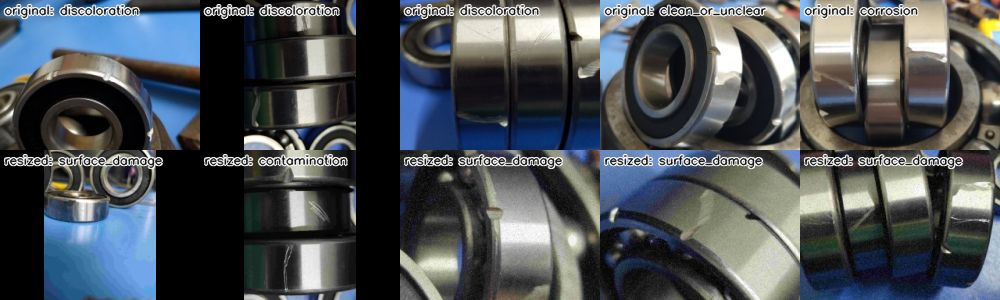

In [7]:
check = pq.read_table(OUTPUT_FILE)
names = json.loads(check.schema.metadata[b'feature_names'])
print(f'{OUTPUT_FILE.name}: {check.num_rows:,} rows x {check.num_columns} columns')
print(f'{len(names):,} features per photo (names are stored in the file metadata)')
print('Columns:', check.schema.names)

preview = check.select(['source_set', 'group_id', 'pseudo_label', 'damage_label']).to_pandas()
print()
print(preview['source_set'].value_counts().to_string())
print(f"Verified damage labels filled in: {int(preview['damage_label'].notna().sum()):,}")

rng = np.random.default_rng(RANDOM_SEED)
chosen = list(rng.choice(np.flatnonzero(preview['source_set'] == 'original'), 5, replace=False))
if (preview['source_set'] == 'resized').any():
    chosen += list(rng.choice(np.flatnonzero(preview['source_set'] == 'resized'), 5, replace=False))

def fit_tile(image: np.ndarray, width: int = 200, height: int = 150) -> np.ndarray:
    scale = min(width / image.shape[1], height / image.shape[0])
    resized_image = cv2.resize(
        image, (round(image.shape[1] * scale), round(image.shape[0] * scale)), interpolation=cv2.INTER_AREA,
    )
    tile = np.zeros((height, width, 3), np.uint8)
    top, left = (height - resized_image.shape[0]) // 2, (width - resized_image.shape[1]) // 2
    tile[top:top + resized_image.shape[0], left:left + resized_image.shape[1]] = resized_image
    return tile


tiles = []
for index in chosen:
    index = int(index)
    thumb = cv2.imdecode(np.frombuffer(check['thumb_jpeg'][index].as_py(), np.uint8), cv2.IMREAD_COLOR)
    tile = fit_tile(thumb)
    caption = f"{preview.at[index, 'source_set']}: {preview.at[index, 'pseudo_label']}"
    cv2.putText(tile, caption, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 2, cv2.LINE_AA)
    cv2.putText(tile, caption, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 0), 1, cv2.LINE_AA)
    tiles.append(tile)
while len(tiles) % 5:
    tiles.append(np.zeros_like(tiles[0]))
grid = np.vstack([np.hstack(tiles[i:i + 5]) for i in range(0, len(tiles), 5)])
ok, grid_jpeg = cv2.imencode('.jpg', grid, [cv2.IMWRITE_JPEG_QUALITY, 80])
display(DisplayImage(data=grid_jpeg.tobytes(), format='jpeg'))

## 6. Baseline model on the one file

This is the cell to replace with your own model: edit `build_model()` and nothing else has to change.

Two rules are built in:

1. **Split on `group_id`, leave sessions out.** There are only about ten capture sessions, so one train/test split would rest on two or three sessions and swing wildly. Instead each of five folds holds out whole sessions. Test photos never share a session with training photos, and resized copies stay with the original they came from. Scores are computed on original photos only.
2. **Use verified labels when they exist.** If `damage_label` has at least two classes with enough examples, the model trains on those. Otherwise it falls back to `pseudo_label`, and the printout says so.

On `pseudo_label`, a good score only means the model reproduces a heuristic rule. **It is not damage-detection accuracy.** Fill in `data/raw/opencv/image_labels.csv`, re-run this notebook, and the same cell trains on real labels.

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, classification_report, f1_score
from sklearn.model_selection import GroupKFold

N_FOLDS = 5


def build_model():
    # Replace with your own model. It only needs fit(X, y) and predict(X).
    return RandomForestClassifier(
        n_estimators=300, class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_SEED,
    )


data = pq.read_table(OUTPUT_FILE)
meta = data.drop_columns(['thumb_jpeg', 'features']).to_pandas()
X = data['features'].combine_chunks().values.to_numpy().reshape(data.num_rows, -1)

verified = meta['damage_label'].notna() & meta['damage_label'].astype(str).str.strip().ne('')
verified_counts = meta.loc[verified, 'damage_label'].value_counts()
use_verified = int((verified_counts >= MIN_VERIFIED_PER_CLASS).sum()) >= 2

if use_verified:
    TARGET, rows = 'damage_label', np.flatnonzero(verified.to_numpy())
    print('Training on VERIFIED damage labels:')
    print(verified_counts.to_string())
else:
    TARGET, rows = 'pseudo_label', np.arange(len(meta))
    print('No usable verified labels yet, so this trains on the heuristic pseudo_label.')
    print('Scores below show how well the model reproduces a rule, NOT damage-detection accuracy.')

y = meta[TARGET].to_numpy()
groups = meta['group_id'].to_numpy()
group_count = len(set(groups[rows]))
if group_count < 2:
    raise ValueError('Need at least two capture groups to hold one out.')

# Leave-sessions-out cross-validation: each fold holds out whole capture sessions.
splitter = GroupKFold(n_splits=min(N_FOLDS, group_count))
fold_scores, pooled_true, pooled_predicted = [], [], []
for fold, (train_pos, test_pos) in enumerate(splitter.split(rows, groups=groups[rows]), 1):
    train_rows, test_rows = rows[train_pos], rows[test_pos]
    test_rows = test_rows[meta['source_set'].to_numpy()[test_rows] == 'original']  # judge on real photos only
    if len(test_rows) == 0:
        continue
    assert not set(groups[train_rows]) & set(groups[test_rows]), 'a capture session is on both sides of the split'
    row = {'fold': fold, 'test photos': len(test_rows)}
    for name, model in (('baseline', DummyClassifier(strategy='most_frequent')), ('build_model()', build_model())):
        model.fit(X[train_rows], y[train_rows])
        predicted = model.predict(X[test_rows])
        row[f'{name} macro F1'] = f1_score(y[test_rows], predicted, average='macro', zero_division=0)
        row[f'{name} balanced acc'] = balanced_accuracy_score(y[test_rows], predicted)
        if name == 'build_model()':
            pooled_true.append(y[test_rows])
            pooled_predicted.append(predicted)
    fold_scores.append(row)

scores = pd.DataFrame(fold_scores).set_index('fold')
print()
print(f'Leave-sessions-out cross-validation, {len(scores)} folds (baseline = always predict the most common class):')
print(scores.round(3).to_string())
print()
print('Mean across folds:')
print(scores.drop(columns='test photos').mean().round(3).to_string())
print()
print('All held-out photos pooled, build_model():')
print(classification_report(np.concatenate(pooled_true), np.concatenate(pooled_predicted), zero_division=0))

No usable verified labels yet, so this trains on the heuristic pseudo_label.
Scores below show how well the model reproduces a rule, NOT damage-detection accuracy.



Leave-sessions-out cross-validation, 5 folds (baseline = always predict the most common class):
      test photos  baseline macro F1  baseline balanced acc  build_model() macro F1  build_model() balanced acc
fold                                                                                                           
1             666              0.061                   0.20                   0.133                       0.241
2             332              0.105                   0.25                   0.110                       0.252
3             329              0.012                   0.20                   0.066                       0.234
4             254              0.006                   0.20                   0.006                       0.200
5             260              0.128                   0.20                   0.138                       0.205

Mean across folds:
baseline macro F1             0.062
baseline balanced acc         0.210
build_model() macro F1     

## Limits and next steps

- **Mining provenance is unverified.** The photos show bearings on a table. Confirm where they were taken before any mining-equipment claim.
- **Labels are the blocker.** Until someone fills `damage_label` in `data/raw/opencv/image_labels.csv`, no model here can say anything about real damage. Check each class by eye, and keep the heuristic `pseudo_label` out of any reported result.
- **The heuristics are weak.** In earlier spot-checks, contamination and surface damage were confused (scratches and debris both look dark), and the bearings' black rubber seals add dark pixels everywhere.
- **Group splits, not row splits.** Always split on `group_id`. A random row split would put near-identical photos on both sides.
- **No future-damage claim.** These are single, undated-in-practice snapshots. Predicting damage before it appears needs repeated dated photos of the same machine and a later outcome, as `OpenCV_Mining_Equipment_Damage.ipynb` explains.
- **Usage permission** is marked unconfirmed in the manifest. Confirm it before sharing the photos or the one-file dataset.